# Credit Scoring Model: Exploratory Data Analysis
**Project:** Credit Scoring Model for Private Debt
**Dataset:** Credit Risk Dataset from Kaggle (laotse/credit-risk-dataset)
**Author:** Patrick Rich Teye

---
This notebook covers the full EDA phase of the credit scoring model:
1. Load and inspect the dataset
2. Understand shape, data types, and statistical summary
3. Identify and analyze missing values
4. Examine class balance (default vs non-default)

All charts are saved to the `plots/` folder.

---
*Personal project built on a public dataset. It uses no proprietary, client or employer data and does not represent the methods or views of any organisation.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 1. Load Dataset
**Relevance:** This dataset contains loan amounts, sector/intent of borrowing, loan grade, interest rates, and a binary default label which closely mirrors the features used in SME private debt credit assessment.

In [2]:
df = pd.read_csv('credit_risk_dataset.csv')

print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(10)

Dataset loaded: 32,581 rows, 12 columns


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
8,24,83000,RENT,8.0,PERSONAL,A,35000,8.90,1,0.42,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3


## 2. Initial Exploration
Inspect column names, data types, and a statistical summary to understand what we are working with.

In [3]:
# Column names and data types
print("=" * 50)
print("COLUMN NAMES & DATA TYPES")
print("=" * 50)
print(df.dtypes)

print()
print("=" * 50)
print("STATISTICAL SUMMARY — NUMERICAL COLUMNS")
print("=" * 50)
df.describe().round(2)

COLUMN NAMES & DATA TYPES
person_age                      int64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

STATISTICAL SUMMARY — NUMERICAL COLUMNS


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


## 3. Missing Values Analysis
Missing data in credit scoring models is not trivial. In a private debt context, missing values in key fields like income, employment length, or interest rate can signal data quality issues or borrower profile gaps — both of which affect risk assessment.

Columns with missing values:
                   Missing Count  Missing (%)
loan_int_rate               3116         9.56
person_emp_length            895         2.75


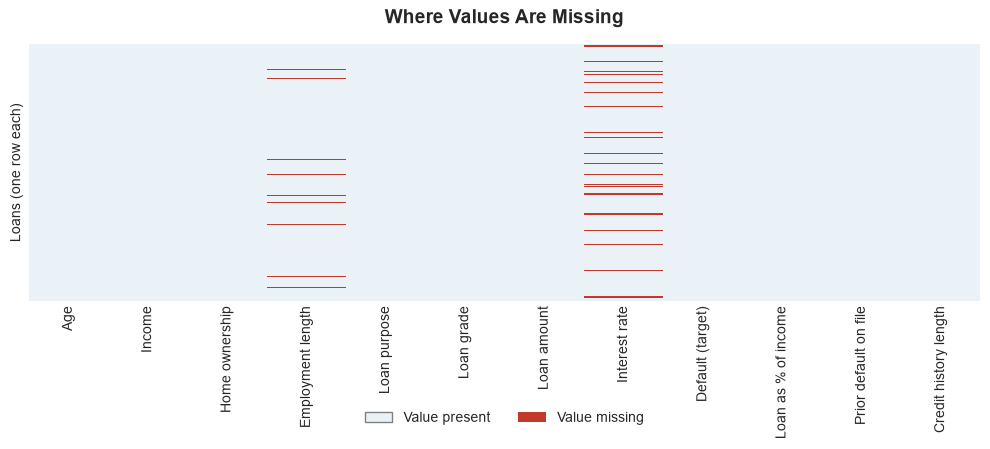

Chart saved to plots/missing_values_heatmap.png


In [4]:
# Calculate missing values
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing (%)': missing_pct.round(2)
}).sort_values('Missing Count', ascending=False)

missing_df = missing_df[missing_df['Missing Count'] > 0]

if missing_df.empty:
    print("No missing values found in the dataset.")
else:
    print("Columns with missing values:")
    print(missing_df)

# Visualize: one row per loan, one column per field, red where the value is missing
COLUMN_LABELS = {
    'person_age': 'Age',
    'person_income': 'Income',
    'person_home_ownership': 'Home ownership',
    'person_emp_length': 'Employment length',
    'loan_intent': 'Loan purpose',
    'loan_grade': 'Loan grade',
    'loan_amnt': 'Loan amount',
    'loan_int_rate': 'Interest rate',
    'loan_status': 'Default (target)',
    'loan_percent_income': 'Loan as % of income',
    'cb_person_default_on_file': 'Prior default on file',
    'cb_person_cred_hist_length': 'Credit history length',
}
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df.isnull().rename(columns=COLUMN_LABELS), yticklabels=False, cbar=False,
            cmap=['#EAF2F8', '#C0392B'], ax=ax)
ax.set_ylabel('Loans (one row each)')
ax.legend(handles=[Patch(facecolor='#EAF2F8', edgecolor='grey', label='Value present'),
                   Patch(facecolor='#C0392B', label='Value missing')],
          loc='upper center', bbox_to_anchor=(0.5, -0.38), ncol=2, frameon=False)
ax.set_title('Where Values Are Missing', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../plots/missing_values_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved to plots/missing_values_heatmap.png")

## 4. Class Balance: Default vs Non-Default
In credit scoring, class imbalance is common and important to flag early. A heavily imbalanced dataset (e.g. 95% non-default, 5% default) requires specific handling in model training otherwise the model learns to predict the majority class and misses actual defaults entirely.

In a private debt fund context, missing a true default is far more costly than a false positive.

CLASS DISTRIBUTION
-----------------------------------
Non-Default (0): 25,473  (78.2%)
Default     (1): 7,108  (21.8%)
Imbalance ratio: 3.6:1


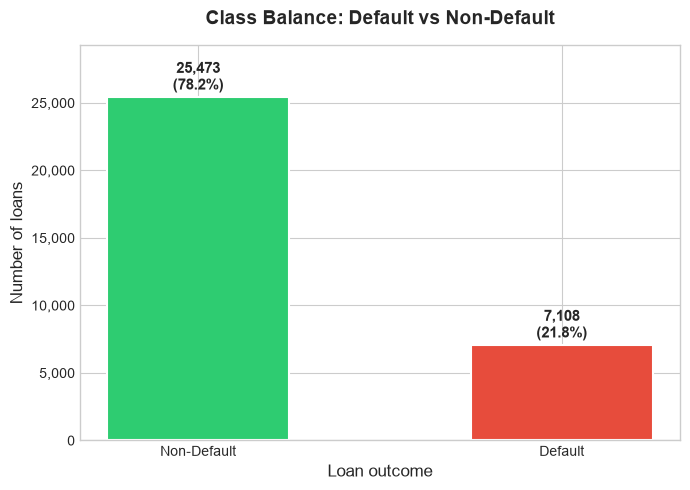

Chart saved to plots/class_balance.png


In [5]:
# Class distribution
class_counts = df['loan_status'].value_counts()
class_pct = df['loan_status'].value_counts(normalize=True) * 100

print("CLASS DISTRIBUTION")
print("-" * 35)
print(f"Non-Default (0): {class_counts[0]:,}  ({class_pct[0]:.1f}%)")
print(f"Default     (1): {class_counts[1]:,}  ({class_pct[1]:.1f}%)")
print(f"Imbalance ratio: {class_counts[0]/class_counts[1]:.1f}:1")

# Plot
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    ['Non-Default', 'Default'],
    [class_counts[0], class_counts[1]],
    color=['#2ecc71', '#e74c3c'],
    edgecolor='white',
    linewidth=1.5,
    width=0.5
)
ax.set_title('Class Balance: Default vs Non-Default', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Loan outcome', fontsize=12)
ax.set_ylabel('Number of loans', fontsize=12)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.set_ylim(0, class_counts.max() * 1.15)
for bar, count, pct in zip(bars, [class_counts[0], class_counts[1]], [class_pct[0], class_pct[1]]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f'{count:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('../plots/class_balance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved to plots/class_balance.png")

## 5. Default Rate by Loan Sector
In a private debt fund, capital is deployed across sectors including agribusiness, healthcare, renewable energy, and infrastructure. Understanding which sectors carry higher default risk is foundational to the scoring model.

The `loan_intent` column in this dataset is used as a sector proxy.

DEFAULT RATE BY SECTOR
-------------------------------------------------------
      loan_intent  Total_Loans  Total_Defaults  Default_Rate_%
DEBTCONSOLIDATION         5212            1490            28.6
          MEDICAL         6071            1621            26.7
  HOMEIMPROVEMENT         3605             941            26.1
         PERSONAL         5521            1098            19.9
        EDUCATION         6453            1111            17.2
          VENTURE         5719             847            14.8


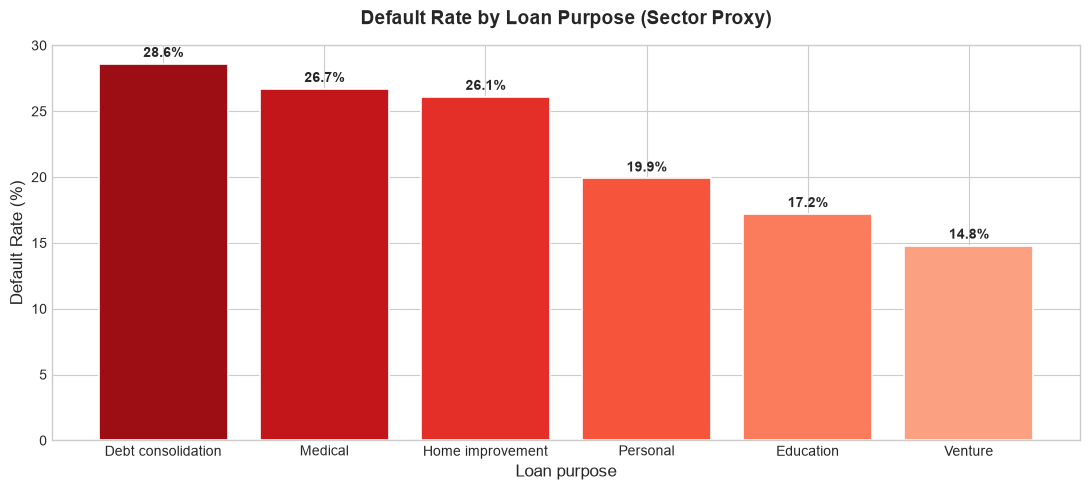

Chart saved to plots/default_rate_by_sector.png


In [6]:
# Default rate by sector
sector_default = df.groupby('loan_intent')['loan_status'].agg(
    Default_Rate='mean',
    Total_Loans='count',
    Total_Defaults='sum'
).reset_index()

sector_default['Default_Rate_%'] = (sector_default['Default_Rate'] * 100).round(1)
sector_default = sector_default.sort_values('Default_Rate_%', ascending=False)

print("DEFAULT RATE BY SECTOR")
print("-" * 55)
print(sector_default[['loan_intent', 'Total_Loans', 'Total_Defaults', 'Default_Rate_%']].to_string(index=False))

# Plot
PURPOSE_LABELS = {
    'DEBTCONSOLIDATION': 'Debt consolidation',
    'HOMEIMPROVEMENT': 'Home improvement',
    'MEDICAL': 'Medical',
    'PERSONAL': 'Personal',
    'EDUCATION': 'Education',
    'VENTURE': 'Venture',
}
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(
    sector_default['loan_intent'].map(PURPOSE_LABELS),
    sector_default['Default_Rate_%'],
    color=sns.color_palette('Reds_r', len(sector_default) + 2)[:len(sector_default)],
    edgecolor='white',
    linewidth=1.2
)
ax.set_title('Default Rate by Loan Purpose (Sector Proxy)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Loan purpose', fontsize=12)
ax.set_ylabel('Default Rate (%)', fontsize=12)
for bar, pct in zip(bars, sector_default['Default_Rate_%']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{pct}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig('../plots/default_rate_by_sector.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved to plots/default_rate_by_sector.png")

## 6. Initial Observations

After this first EDA pass, here are key findings before moving into feature engineering.

| Observation | Detail |
|---|---|
| Dataset size | 32,581 rows, 12 columns |
| Missing values | 2 columns affected: 9.56% of `loan_int_rate` and 2.75% of `person_emp_length` |
| Class balance | 78.2% non-default, 21.8% default with imbalance ratio 3.6:1 |
| Highest-risk sector | Sector with the highest default rate is debt consolidation (28.6%) where loans are taken to repay other loans |
| Lowest-risk sector | Sector with the lowest default rate is venture (14.8%) where loans are taken to fund new businesses |

---
